# Atari Analysis: Breakout Survival Time

## My Question
For a random-action player in **Atari Breakout**, what is the probability that the **average first-life survival time across 100 fresh games exceeds 2 seconds**? What is the 90th percentile of that average, and what interval contains its middle 95%?

I use a fitted normal distribution for the average, and compare its answers with a bootstrap simulation based on **1,000 actual game runs**. The normal model is an approximation, not an assumption that individual game durations are normal.

## My Simulation
1. **Random variable:** Let $T$ be simulated seconds from reset to the first lost life under the policy below. The variable of interest is $X=(T_1+\cdots+T_{100})/100$, the average first-life survival time in a batch of 100 fresh games. Time is modeled as continuous and nonnegative. The emulator actually measures integer frames, so the recorded times and their averages have fine, discrete resolution; they are not mathematically continuous. We use a continuous normal approximation to these averages.
2. **One game run:** Reset Breakout with a new seed, send FIRE once, and then choose uniformly from the available actions at each step. Stop at the first lost life, game termination, or a 120-second safety cap. Outcomes are measured durations, rather than wins or losses. Time includes the initial launch sequence and measures emulated game time, not computer execution speed.
3. **One bootstrap trial:** Draw 100 durations with replacement from the 1,000 recorded game runs and average them. Repeat 1,000 times. This estimates the distribution of $X$ without running 100,000 games. Resampling introduces no new game observations and inherits the limitations of the original sample.
4. **Normal model:** Independent games with finite variance motivate $X\approx N(\mu_T,\sigma_T^2/100)$ by the central limit theorem. Estimate $\mu_T$ and $\sigma_T$ from the actual game runs. A histogram, Q–Q plot, and empirical comparisons check the usefulness of this approximation.

## Setup
Run the installation cell once if needed, then restart the kernel before continuing. The analysis runs headlessly; no game window or animation is required. Recent `ale-py` releases include the ROMs.

The environment uses the standard Breakout v5 settings: four emulator frames per action and sticky-action probability 0.25. Sources: [Breakout documentation](https://ale.farama.org/environments/breakout/) and [ALE installation](https://ale.farama.org/getting-started/).

In [1]:
# Uncomment only if these packages are missing, then restart the kernel.
# %pip install "gymnasium[atari]" numpy pandas matplotlib seaborn scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)
SEED = 42
N_GAMES = 1_000
BATCH_SIZE = 100
N_BOOTSTRAP = 1_000
THRESHOLD_SECONDS = 2.0
FPS = 60  # nominal emulated frames per second; not wall-clock speed
MAX_SECONDS = 120
MAX_FRAMES = FPS * MAX_SECONDS
rng_actions = np.random.default_rng(SEED)
rng_bootstrap = np.random.default_rng(SEED + 1)
print(f"Gymnasium {gym.__version__}; ALE {ale_py.__version__}")

Gymnasium 1.4.0; ALE 0.12.1


## My Analysis
### 1. Run Breakout 1,000 times
Use RAM observations for speed. Record emulator frame counts directly, so the duration does not depend on how fast this computer runs. Each reset receives a distinct seed. A safety-capped run is flagged; the notebook refuses to silently treat capped durations as uncensored first-life times.

In [3]:
env = gym.make(
    "ALE/Breakout-v5", obs_type="ram", frameskip=4,
    repeat_action_probability=0.25,
)
records = []
try:
    fire_action = env.unwrapped.get_action_meanings().index("FIRE")
    ale = env.unwrapped.ale
    for game in range(N_GAMES):
        _, info = env.reset(seed=SEED + game)
        initial_lives = info["lives"]
        start_frame = ale.getEpisodeFrameNumber()
        first_action = True
        while True:
            action = fire_action if first_action else int(rng_actions.integers(env.action_space.n))
            first_action = False
            _, reward, terminated, truncated, info = env.step(action)
            elapsed_frames = ale.getEpisodeFrameNumber() - start_frame
            lost_life = info["lives"] < initial_lives
            if lost_life or terminated or truncated or elapsed_frames >= MAX_FRAMES:
                # A life loss observed at the cap is still an observed event.
                censored = not lost_life
                records.append({
                    "game": game + 1,
                    "frames": elapsed_frames,
                    "seconds": elapsed_frames / FPS,
                    "lost_life": lost_life,
                    "censored": censored,
                })
                break
        if (game + 1) % 250 == 0:
            print(f"Completed {game + 1:,} / {N_GAMES:,} actual game runs")
finally:
    env.close()

games = pd.DataFrame(records)
assert len(games) == N_GAMES
assert np.isfinite(games["seconds"]).all() and (games["seconds"] > 0).all()
print(f"Censored runs: {games['censored'].sum()}")
if games["censored"].any():
    raise RuntimeError("Some lives did not end naturally. Increase the cap and rerun before analyzing.")
display(games.head())
display(games["seconds"].describe().to_frame("First-life duration (seconds)"))

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Completed 250 / 1,000 actual game runs


Completed 500 / 1,000 actual game runs


Completed 750 / 1,000 actual game runs


Completed 1,000 / 1,000 actual game runs
Censored runs: 0


,game,frames,seconds,lost_life,censored
0,1,100,1.666667,True,False
1,2,100,1.666667,True,False
2,3,100,1.666667,True,False
3,4,100,1.666667,True,False
4,5,288,4.800000,True,False


,First-life duration (seconds)
count,1000.000000
mean,2.089667
std,1.271447
min,1.666667
25%,1.666667
50%,1.666667
75%,1.666667
max,11.933333


### 2. Simulate batch averages and fit the normal model
The 1,000 bootstrapped averages each represent a hypothetical batch of 100 games. Set $\hat\mu_X=\bar T$ and $\hat\sigma_X=s_T/\sqrt{100}$. This is the spread of **batch averages**, not the spread of individual game durations. The fitted distribution is $N(\hat\mu_X,\hat\sigma_X^2)$.

In [4]:
durations = games["seconds"].to_numpy()
bootstrap_means = rng_bootstrap.choice(
    durations, size=(N_BOOTSTRAP, BATCH_SIZE), replace=True
).mean(axis=1)
mu = sum(durations) / len(durations)
sd_individual = (sum((value - mu) ** 2 for value in durations) / (len(durations) - 1)) ** 0.5
sigma = sd_individual / np.sqrt(BATCH_SIZE)
assert sigma > 0
model = stats.norm(loc=mu, scale=sigma)
print(f"Individual-game mean: {mu:.4f} seconds")
print(f"Individual-game SD: {sd_individual:.4f} seconds")
print(f"Normal model for batch averages: mean = {mu:.4f}, SD = {sigma:.4f} seconds")
print(f"Bootstrap averages: mean = {bootstrap_means.mean():.4f}, SD = {bootstrap_means.std(ddof=1):.4f} seconds")

Individual-game mean: 2.0897 seconds
Individual-game SD: 1.2714 seconds
Normal model for batch averages: mean = 2.0897, SD = 0.1271 seconds
Bootstrap averages: mean = 2.0890, SD = 0.1211 seconds


### 2a. Calculate the mean using the formula
For the $n=1{,}000$ simulated batch averages, use:
$$\bar{x}=\frac{\sum_{i=1}^{n}x_i}{n}.$$
Here each $x_i$ is one bootstrap average of 100 game durations. This describes the histogram of batch averages.

In [5]:
x_values = bootstrap_means
n_values = len(x_values)
sum_x = sum(x_values)
sample_mean = sum_x / n_values
print(f"Number of batch averages (n): {n_values:,}")
print(f"Mean = sum(x) / n = {sample_mean:.4f} seconds")

Number of batch averages (n): 1,000
Mean = sum(x) / n = 2.0890 seconds


### 2b. Calculate the sample standard deviation using the formula
$$s=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}.$$
Subtract the mean from each value, square the differences, add them, divide by $n-1$, and take the square root. This is the **sample standard deviation**, so the denominator is $n-1$.

These empirical summary statistics describe the bootstrap histogram. The fitted normal curve above uses the original game mean and the estimated standard deviation of a 100-game average, $s_T/\sqrt{100}$; the two sets of values should be close but need not be identical.

In [6]:
squared_deviations = [(value - sample_mean) ** 2 for value in x_values]
sum_squared_deviations = sum(squared_deviations)
sample_variance = sum_squared_deviations / (n_values - 1)
sample_sd = sample_variance ** 0.5
print(f"Sample variance: {sample_variance:.6f} seconds squared")
print(f"Sample standard deviation: {sample_sd:.4f} seconds")

# Check the formula calculations against NumPy (ddof=1 uses n - 1).
assert np.isclose(sample_mean, np.mean(x_values))
assert np.isclose(sample_sd, np.std(x_values, ddof=1))

Sample variance: 0.014669 seconds squared
Sample standard deviation: 0.1211 seconds


### 3. Estimate and calculate the probability, percentile, and interval
For the event $X>2$, calculate $z=(2-\hat\mu_X)/\hat\sigma_X$ and $P(X>2)\approx1-\Phi(z)$. The 90th percentile is $\hat\mu_X+z_{0.90}\hat\sigma_X$. The middle 95% interval uses the 2.5th and 97.5th percentiles.

These are plug-in estimates for the distribution of a **future batch average**, not a confidence interval for an unknown population mean. Bootstrap frequencies estimate the same quantities from resampled data.

In [7]:
z = (THRESHOLD_SECONDS - mu) / sigma
p_normal = model.sf(THRESHOLD_SECONDS)
p_empirical = np.mean(bootstrap_means > THRESHOLD_SECONDS)
p90_normal = model.ppf(0.90)
p90_empirical = np.quantile(bootstrap_means, 0.90)
interval_normal = model.ppf([0.025, 0.975])
interval_empirical = np.quantile(bootstrap_means, [0.025, 0.975])
mc_se = np.sqrt(p_empirical * (1 - p_empirical) / N_BOOTSTRAP)
results = pd.DataFrame({
    "Quantity": ["P(batch average > 2 seconds)", "90th percentile (seconds)",
                 "Middle 95% lower bound (seconds)", "Middle 95% upper bound (seconds)"],
    "Normal approximation": [p_normal, p90_normal, *interval_normal],
    "Bootstrap estimate": [p_empirical, p90_empirical, *interval_empirical],
})
display(results.style.format({"Normal approximation": "{:.4f}", "Bootstrap estimate": "{:.4f}"}))
print(f"z score for 2 seconds: {z:.3f}")
print(f"Normal probability: {p_normal:.2%}; bootstrap probability: {p_empirical:.2%}")
print(f"Bootstrap Monte Carlo SE: {mc_se:.2%} (conditional on the observed sample)")
print("This SE measures resampling noise; it excludes uncertainty from having only 1,000 actual games.")

,Quantity,Normal approximation,Bootstrap estimate
0,P(batch average > 2 seconds),0.7597,0.7560
1,90th percentile (seconds),2.2526,2.2494
2,Middle 95% lower bound (seconds),1.8405,1.8686
3,Middle 95% upper bound (seconds),2.3389,2.3447


z score for 2 seconds: -0.705
Normal probability: 75.97%; bootstrap probability: 75.60%
Bootstrap Monte Carlo SE: 1.36% (conditional on the observed sample)
This SE measures resampling noise; it excludes uncertainty from having only 1,000 actual games.


### 4a. Set the Seaborn theme
Seaborn provides the histogram and plotting theme. Matplotlib draws the fitted normal density, mean, threshold, labels, and shaded event area.

In [8]:
sns.set_theme(style="whitegrid", context="notebook")

### 4b. Prepare the normal density
Evaluate the fitted normal model over a grid of possible batch-average times.

In [9]:
x = np.linspace(min(bootstrap_means.min(), mu - 4*sigma, THRESHOLD_SECONDS),
                max(bootstrap_means.max(), mu + 4*sigma, THRESHOLD_SECONDS), 600)

### 4c. Graph the normal distribution with Seaborn and Matplotlib
The curve is the normal approximation. The histogram shows bootstrap averages, and the shaded area estimates the probability of a batch average above two seconds.

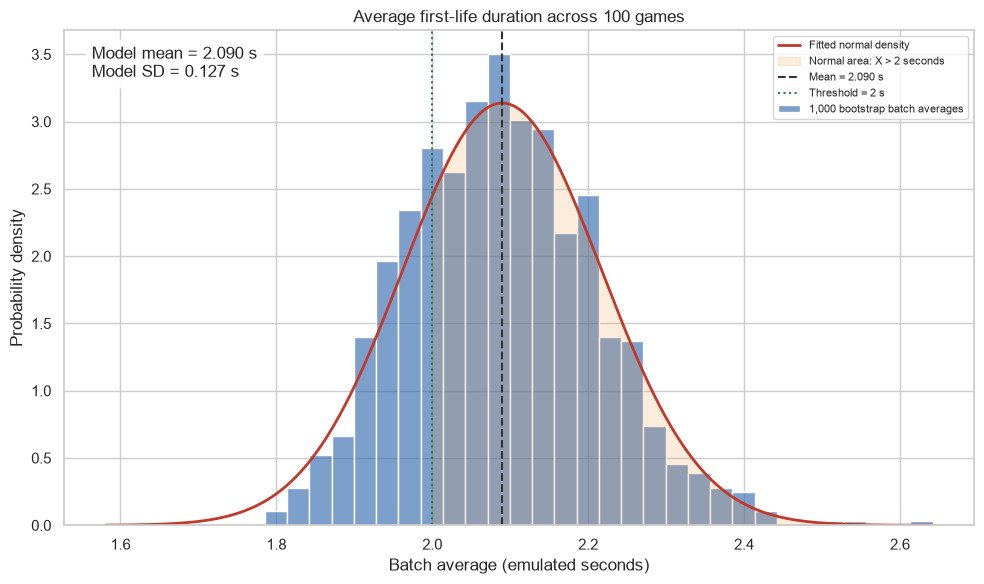

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(x=bootstrap_means, bins=30, stat="density", alpha=0.65,
             color="#386cb0", edgecolor="white", ax=ax,
             label="1,000 bootstrap batch averages")
ax.plot(x, model.pdf(x), color="#c0392b", linewidth=2, label="Fitted normal density")
ax.fill_between(x, model.pdf(x), where=x > THRESHOLD_SECONDS,
                alpha=0.18, color="#ed9b40", label="Normal area: X > 2 seconds")
ax.axvline(mu, color="#333333", linestyle="--", label=f"Mean = {mu:.3f} s")
ax.axvline(THRESHOLD_SECONDS, color="#25804a", linestyle=":", label="Threshold = 2 s")
ax.set(title="Average first-life duration across 100 games",
       xlabel="Batch average (emulated seconds)", ylabel="Probability density")
ax.text(0.03, 0.97, f"Model mean = {mu:.3f} s\nModel SD = {sigma:.3f} s",
        transform=ax.transAxes, va="top", bbox=dict(facecolor="white", alpha=0.9))
ax.legend(loc="upper right", fontsize=8)

fig.tight_layout()
plt.show()

### 4d. Check the normal approximation
The Q–Q plot compares the bootstrap averages with the fitted normal distribution.

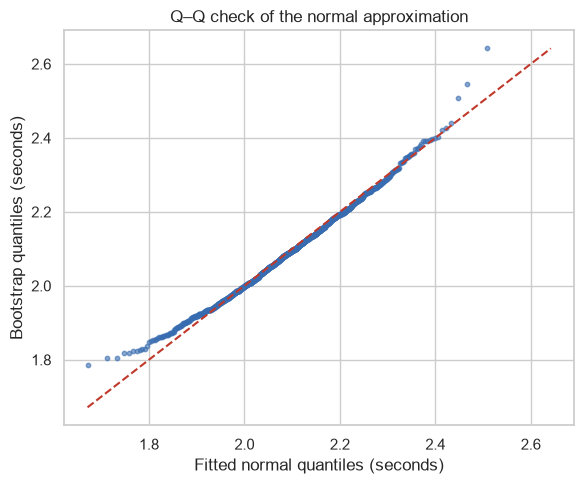

Individual-duration skewness: 3.797
Batch-average bootstrap skewness: 0.343
Absolute probability difference: 0.37%


In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
q = (np.arange(1, N_BOOTSTRAP + 1) - 0.5) / N_BOOTSTRAP
expected = model.ppf(q)
observed = np.sort(bootstrap_means)
ax.scatter(expected, observed, s=10, alpha=0.6, color="#386cb0")
lo = min(expected.min(), observed.min())
hi = max(expected.max(), observed.max())
ax.plot([lo, hi], [lo, hi], "--", color="#c0392b")
ax.set(title="Q–Q check of the normal approximation",
            xlabel="Fitted normal quantiles (seconds)", ylabel="Bootstrap quantiles (seconds)")
fig.tight_layout()
plt.show()

print(f"Individual-duration skewness: {stats.skew(durations, bias=False):.3f}")
print(f"Batch-average bootstrap skewness: {stats.skew(bootstrap_means, bias=False):.3f}")
print(f"Absolute probability difference: {abs(p_normal - p_empirical):.2%}")
assert 0 <= p_normal <= 1 and 0 <= p_empirical <= 1
assert interval_normal[0] < p90_normal < interval_normal[1]

## My Conclusion

For a random-action player in Atari Breakout, the **theoretical probability from the fitted normal model** that the average first-life survival time across 100 games exceeds 2 seconds is **75.97%**. The **empirical probability is 75.60%**, because **756 of the 1,000 bootstrap batch averages** exceeded 2 seconds. The bootstrap trials resampled durations from **1,000 actual game runs**; they are not 1,000 additional batches of new games.

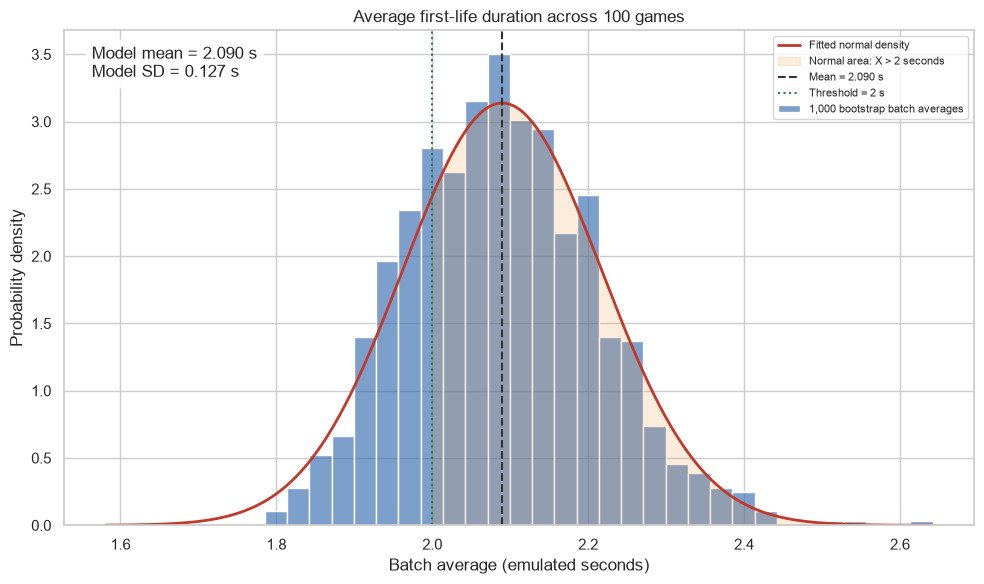

The blue histogram shows the distribution of the bootstrap batch averages. Its **sample mean is 2.0890 seconds** and its **sample standard deviation is 0.1211 seconds**. The red normal curve uses a **model mean of 2.0897 seconds** and a **model standard deviation of 0.1271 seconds**, labeled on the graph. The shaded area to the right of the green 2-second threshold represents the theoretical probability being calculated.

Most batch averages lie near the mean, and about three quarters exceed 2 seconds. The histogram generally follows the bell-shaped normal curve, although some skewness remains. The theoretical and empirical probabilities differ by only **0.37 percentage points**, supporting the normal approximation for this event and the conclusion that a 100-game average above 2 seconds is likely. This does not imply that individual game durations are normally distributed. The results apply to the simulated random-action policy and depend on the normal approximation and the observed sample.

*These values summarize the saved seeded simulation.*